In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


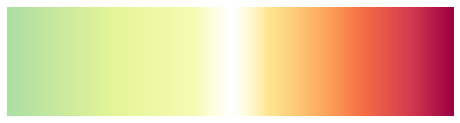

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap

# Load the spectral colormap and split it into two halves
spectral_cmap = cm.get_cmap('Spectral_r', 256)
colors = spectral_cmap(np.linspace(0, 1, 256))

# Split the colormap into two halves
negative_side = colors[128-50:128]
positive_side = colors[128:]

x_old = np.linspace(0, 1, 50)  # Original 50 indices
x_new = np.linspace(0, 1, 128)  # Target 128 indices
negative_side_interpolated = np.zeros((128, 4))  # RGBA has 4 channels
for i in range(4):  # Interpolating R, G, B, and Alpha separately
    negative_side_interpolated[:, i] = np.interp(x_new, x_old, negative_side[:, i])

negative_side = negative_side_interpolated

# Define the transition to white with 20 colors on each side
transition_length = 20

# Create the transition from negative side to white
negative_transition = np.array([
    (1 - i / transition_length) * negative_side[-transition_length + i] + (i / transition_length) * np.array([1, 1, 1, 1])
    for i in range(transition_length)
])

# Create the transition from white to the positive side
positive_transition = np.array([
    (i / transition_length) * positive_side[i] + (1 - i / transition_length) * np.array([1, 1, 1, 1])
    for i in range(transition_length)
])

# Concatenate the transitions and the original spectral colors
new_blend_colors = np.concatenate((negative_side[:-transition_length], negative_transition, [[1, 1, 1, 1]], positive_transition, positive_side[transition_length:]), axis=0)

# Create the new colormap with the smooth transition
new_cmap = LinearSegmentedColormap.from_list('smooth_spectral_white_center', new_blend_colors)

# Display the new colormap
gradient = np.linspace(0, 1, len(new_blend_colors)).reshape(1, len(new_blend_colors))
gradient = np.vstack([gradient, gradient])

fig, ax = plt.subplots(figsize=(8, 2))
ax.imshow(gradient, aspect='auto', cmap=new_cmap)
ax.set_axis_off()
plt.show()


In [8]:
import pickle
def save_pickle(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_pickle(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model

In [9]:
prefix = '/mnt/staging/'
path_config = str(PREPARES / "config") + "/"
save_pickle(new_cmap,path_config+'sunset_cmap')

# neural activity postive side

/home/wx2203/anaconda3/lib/python3.7/site-packages/pandas/compat/_optional.py:138: UserWarning: Pandas requires version '2.7.0' or newer of 'numexpr' (version '2.6.9' currently installed).
  warnings.warn(msg, UserWarning)


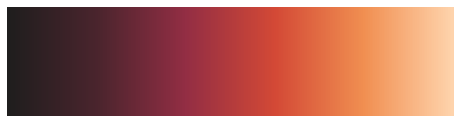

In [4]:
from matplotlib import cm
import seaborn as sns
icefire = cm.get_cmap('icefire')
viridis = cm.get_cmap('viridis')


from matplotlib.colors import LinearSegmentedColormap
# Define the refined colors for a more aesthetically pleasing diverging colormap
refined_colors = [
icefire(0.5),
icefire(0.6),
    icefire(0.7),
    icefire(0.8),
    icefire(0.9),
    icefire(0.9999999999999),
]

# Create the refined colormap
fire_cmap = LinearSegmentedColormap.from_list("custom_teal_black_gold", refined_colors)

gradient = np.linspace(-1, 1, 256).reshape(1, -1)
gradient = np.vstack((gradient, gradient))

# Generate a sample plot to visualize the refined colormap
fig, ax = plt.subplots(figsize=(8, 2))
ax.imshow(gradient, aspect='auto', cmap=fire_cmap)
ax.set_axis_off()
plt.show()


In [6]:
prefix = '/mnt/staging/'
path_config = str(PREPARES / "config") + "/"
save_pickle(fire_cmap,path_config+'fire_cmap')

In [16]:
# # modify its permissions to make it readable by everyone:
# !chmod 644 /mnt/staging/users/wx2203/data_submission/prepares_data/config/jet_cmap

# diverging cmap for gcamp

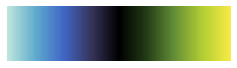

In [5]:
negative_colors_precise = ['#bde7db', '#60abcd', '#4167c7', '#37355c', 'black']
positive_colors_precise = ["black", "#233D16", "#658F38", "#B3CE33", "#F7EA46"]


colors_precise = negative_colors_precise + positive_colors_precise[1:]
diverging_cmap_precise = LinearSegmentedColormap.from_list("DivergingCustomPrecise", colors_precise)

# Plotting the precisely centered diverging colormap
fig, ax = plt.subplots(figsize=(4, 1))
ax.imshow(gradient, aspect='auto', cmap=diverging_cmap_precise, origin='lower')
ax.set_axis_off()
plt.show()


In [6]:
prefix = '/mnt/staging/'
path_config = str(PREPARES / "config") + "/"
save_pickle(diverging_cmap_precise,path_config+'gcamp_diverging_cmap')

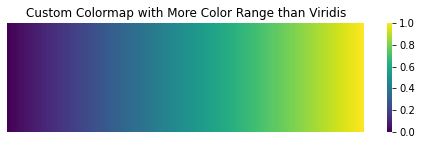

In [12]:
import seaborn as sns
plt.figure(figsize=(8, 2))
sns.heatmap(gradient, cmap='viridis')
plt.axis('off')
plt.title('Custom Colormap with More Color Range than Viridis')
plt.show()

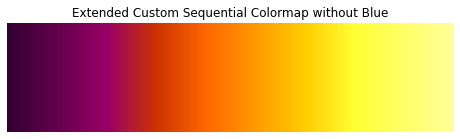

In [4]:
# Define a custom sequential colormap with more colors in the warm spectrum
warm_colors_extended = [
    (0.2, 0.0, 0.2),  # Dark purple
    (0.4, 0.0, 0.3),  # Deep magenta
    (0.6, 0.0, 0.4),  # Magenta
    (0.8, 0.2, 0.0),  # Reddish orange
    (1.0, 0.4, 0.0),  # Orange
    (1.0, 0.6, 0.0),  # Yellow-orange
    (1.0, 0.8, 0.0),  # Yellow
    (1.0, 1.0, 0.2),  # Light yellow
    (1.0, 1.0, 0.4),  # Pale yellow
    (1.0, 1.0, 0.6),  # Very pale yellow
]

custom_sequential_cmap_extended = LinearSegmentedColormap.from_list("custom_sequential_extended", warm_colors_extended)

# Plot the custom extended sequential colormap
plt.figure(figsize=(8, 2))
plt.imshow(gradient, aspect='auto', cmap=custom_sequential_cmap_extended)
plt.axis('off')
plt.title('Extended Custom Sequential Colormap without Blue')
plt.show()


In [5]:
magenta_emphasized_warm_colors = [
    (0.2, 0.0, 0.2),  # Dark purple
    (0.25, 0.0, 0.23), # Purple-magenta
    (0.3, 0.0, 0.25), # Purple-magenta
    (0.35, 0.0, 0.28), # Deep magenta
    (0.4, 0.0, 0.3),  # Deep magenta
    (0.45, 0.05, 0.33), # Magenta
    (0.5, 0.1, 0.35), # Magenta
    (0.55, 0.15, 0.4), # Stronger magenta
    (0.6, 0.2, 0.45),  # Stronger magenta
    (0.65, 0.25, 0.35), # Magenta-red
    (0.7, 0.3, 0.2),  # Red-orange
    (0.75, 0.35, 0.15), # Red-orange
    (0.8, 0.4, 0.1),  # Red-orange
    (0.85, 0.45, 0.0), # Orange
    (0.9, 0.5, 0.0),  # Orange-yellow
    (0.95, 0.55, 0.0),  # Yellow-orange
    (1.0, 0.6, 0.0),  # Yellow-orange
    (1.0, 0.65, 0.1),  # Golden yellow
    (1.0, 0.7, 0.2),  # Golden yellow
    (1.0, 0.75, 0.3),  # Light yellow-orange
    (1.0, 0.8, 0.4),  # Light yellow-orange
    (1.0, 0.85, 0.45),  # Soft yellow
    (1.0, 0.9, 0.5),  # Soft yellow
    (1.0, 0.95, 0.55),  # Pale yellow
    (1.0, 1.0, 0.6),  # Pale yellow
    (0.95, 0.9, 0.5),  # Soft yellow-brown
    (0.9, 0.8, 0.4),  # Soft yellow-brown
    (0.85, 0.75, 0.35), # Golden brown
    (0.8, 0.7, 0.3),  # Golden brown
    (0.75, 0.65, 0.25), # Warm brown
    (0.7, 0.6, 0.2),  # Warm brown
    (0.65, 0.55, 0.2),  # Warm brown
    (0.6, 0.5, 0.2)   # Dark warm brown
]

magenta_emphasized_custom_cmap = LinearSegmentedColormap.from_list("magenta_emphasized_custom_sequential", magenta_emphasized_warm_colors)


In [7]:
prefix = '/mnt/staging/'
path_config = str(PREPARES / "config") + "/"
save_pickle(magenta_emphasized_custom_cmap,path_config+'spectrogram_cmap')

# truncated jet

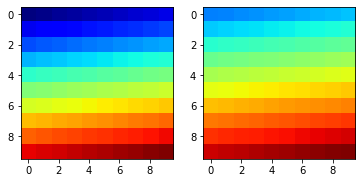

In [4]:
import matplotlib.colors as colors
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)
ax[0].imshow(arr, interpolation='nearest', cmap=cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=new_cmap)
plt.show()

cmap = plt.get_cmap('jet')
new_cmap = truncate_colormap(cmap, 0.25, 1)

In [5]:
prefix = '/mnt/staging/'
path_config = str(PREPARES / "config") + "/"
save_pickle(new_cmap,path_config+'truncated_jet_cmap')